# Key results from the shipped outputs

This notebook reproduces the central numbers of the manuscript from the derived tables in this
repository. It needs neither the GRDC discharge nor any download, and runs in about two minutes.

1. Matching on the observed Volta network: origin events, opportunities, connected fractions and the per-link probability.
2. The Ebro reference: the published statistics recovered from the authors' released catalogue.
3. The availability-aware permutation null on the Volta (fewer permutations than in the paper, for speed).
4. The per-link model against the observed connected shares (Fig. 6a).
5. The reanalysis network and the observing-system experiment (Table 2).

The full analysis is run by `reproduce.sh`; see `REPRODUCIBILITY.md`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "voltaprop").is_dir())   # repository root
sys.path.insert(0, str(ROOT))
from voltaprop import fastmatch as F
from voltaprop.propagation import load_connectivity

TO = ROOT / "output_observational" / "tables"
pd.set_option("display.precision", 4)

## 1. The observed Volta network (18 GRDC gauges, 1961–2007)

In [2]:
ev = pd.read_csv(TO / "SSI_drought_events.csv", parse_dates=["start_date", "end_date"])
vconn = load_connectivity(TO / "upstream_connectivity.csv")
ssi = pd.read_csv(TO / "SSI_daily.csv", parse_dates=["date"], usecols=["node_id", "date", "SSI"])
vrecs = F.build_records(ev, avail=F.availability_from_daily(ssi), nodes=list(vconn))

volta = F.statistics(vrecs, vconn)
print(f"events: {len(ev)} at {ev.node_id.nunique()} stations; directed links: {sum(len(v) for v in vconn.values())}")
pd.Series(volta)

events: 174 at 16 stations; directed links: 22


n_origin_events      104.0000
n_opportunities       40.0000
n_connected           10.0000
n_pairs               10.0000
coverage               0.3846
cf_all                 0.0962
cf_opp                 0.2500
mean_k_observing       1.6750
p_link                 0.1617
mean_chain_size        2.0000
mean_pf_published      0.4000
mean_pf_observing      0.7450
dtype: float64

Expected (manuscript, Sections 3.2.2 and 3.4): 104 origin events, 40 opportunities, 10 connected, coverage 0.385, cf_all 0.096, cf_opp 0.25, mean observing links 1.7, per-link probability 0.162.

## 2. The Ebro reference (Crespillo López et al., 2026)

In [3]:
eb = pd.read_csv(ROOT / "data/ebro/ebro_events.csv", parse_dates=["start_date", "end_date"]).rename(columns={"station_id": "node_id"})
ep = pd.read_csv(ROOT / "data/ebro/ebro_pairs_net_km.csv")
econn = {int(s): [] for s in eb.node_id.unique()}
for _, r in ep.iterrows():
    econn[int(r.origin_station)].append(int(r.upstream_station))
erecs = F.build_records(eb)
ebro = F.statistics(erecs, econn)
pd.DataFrame({"Ebro": pd.Series(ebro), "Volta": pd.Series(volta)})

,Ebro,Volta
n_origin_events,928.0000,104.0000
n_opportunities,928.0000,40.0000
n_connected,525.0000,10.0000
n_pairs,2075.0000,10.0000
coverage,1.0000,0.3846
cf_all,0.5657,0.0962
cf_opp,0.5657,0.2500
mean_k_observing,9.2026,1.6750
p_link,0.1641,0.1617
mean_chain_size,4.9524,2.0000


Published Ebro values: 928 origin events, 525 chains, 2,075 pairs, connected fraction 0.566, mean chain size 4.95, mean propagation fraction 0.418. Per observing link the two basins connect at nearly the same rate (0.164 against 0.162).

## 3. Availability-aware permutation null on the Volta

The paper uses 19,999 permutations (p = 0.050 for cf_opp). Here 999 are drawn, so the p-values carry a Monte Carlo error of about ±0.014.

In [4]:
obs, summary, null = F.null_test(vrecs, vconn, n_perm=999, seed=42)
summary.set_index("statistic").loc[["cf_all", "cf_opp", "p_link"], ["observed", "null_mean", "null_p95", "p"]]

,observed,null_mean,null_p95,p
statistic,,,,
cf_all,0.0962,0.0742,0.1474,0.249
cf_opp,0.2500,0.1322,0.2381,0.041
p_link,0.1617,0.0924,0.1761,0.081


## 4. Per-link model against observed connected shares (Fig. 6a)

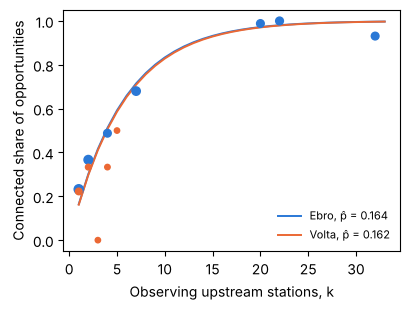

In [5]:
def by_k(recs, conn):
    _, org = F.match(recs, conn)
    opp = org[org.n_observing >= 1]
    g = opp.groupby("n_observing").connected.agg(["size", "mean"])
    return opp, g

fig, ax = plt.subplots(figsize=(4.2, 3.2))
for name, (recs, conn), col in (("Ebro", (erecs, econn), "#2a78d6"), ("Volta", (vrecs, vconn), "#eb6834")):
    opp, g = by_k(recs, conn)
    p = F.link_probability_mle(opp.n_observing.values, opp.connected.values.astype(bool))
    k = np.arange(1, 34)
    ax.plot(k, 1 - (1 - p) ** k, color=col, lw=1.4, label=f"{name}, p̂ = {p:.3f}")
    ax.scatter(g.index, g["mean"], s=12 + 2 * np.sqrt(g["size"]), color=col, zorder=3)
ax.set_xlabel("Observing upstream stations, k"); ax.set_ylabel("Connected share of opportunities")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

## 5. Reanalysis network and observing-system experiment

In [6]:
S = pd.read_csv(ROOT / "output_reanalysis/tables/reanalysis_summary.csv")
S[["label", "n_nodes", "n_events", "n_origin_events", "coverage", "mean_k_observing", "cf_all", "cf_opp", "p_link", "p_cf_opp"]]

,label,n_nodes,n_events,n_origin_events,coverage,mean_k_observing,cf_all,cf_opp,p_link,p_cf_opp
0,main t2500 1961-2020 M5,129,9392,7379,0.9828,13.7248,0.8027,0.8167,0.2303,0.0005
1,density t1000 1961-2020 M5,203,13265,10395,0.9596,18.4267,0.7594,0.7914,0.2229,0.0010
2,density t5000 1961-2020 M5,91,6914,5527,0.9823,12.1757,0.8193,0.8340,0.2326,0.0010
3,vintage t2500 1961-2025 M5,129,10349,8105,0.9829,13.7502,0.8054,0.8195,0.2318,0.0010
4,split t2500 1961-2007 M5,129,6847,5339,0.9837,13.7584,0.8033,0.8166,0.2245,0.0010
5,split t2500 2008-2025 M5,129,3511,2774,0.9813,13.7127,0.8097,0.8251,0.2479,0.0010
6,M3 t2500 1961-2020,129,9392,7379,0.9828,13.7248,0.8303,0.8449,0.2756,0.0010
7,M7 t2500 1961-2020,129,9392,7379,0.9828,13.7248,0.6650,0.6766,0.1040,0.0010


In [7]:
BN = json.load(open(ROOT / "output_reanalysis/benchmark_numbers.json"))
pd.DataFrame(BN["osse"])[["scenario", "n_origin_events", "coverage", "mean_k_observing", "cf_all", "cf_opp", "p_link",
                          "p_cf_all", "p_cf_opp", "p_p_link"]]

,scenario,n_origin_events,coverage,mean_k_observing,cf_all,cf_opp,p_link,p_cf_all,p_cf_opp,p_p_link
0,continuous,478,0.9728,2.6323,0.6381,0.6559,0.3508,0.0005,0.0005,0.0005
1,masked to observed days,171,0.5789,1.8687,0.2573,0.4444,0.3128,0.3855,0.1380,0.1315
2,refitted on observed days,141,0.6454,1.8242,0.2128,0.3297,0.2115,0.2090,0.1965,0.2835


Sampling the dense simulation through the observed gauges, with their gaps, removes the test's ability to detect propagation that is present by construction (Section 3.5, Table 2).